# Drinking Waste YOLO 분할별 통계

AluCan은 can, Glass는 glass, HDPEM과 PET는 plastic으로 합쳤습니다. general 라벨은 없습니다. train/val/test별 이미지 수와 객체 수를 표시합니다.


In [2]:
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

root = next((path for path in (Path.cwd(), Path.cwd() / 'drinking_waste_yolo',
                                Path.cwd() / 'data' / 'drinking_waste_yolo')
             if (path / 'labels').is_dir()), None)
assert root is not None, f'Dataset folder not found under {Path.cwd()}'
names = {0: 'general', 1: 'plastic', 2: 'can', 3: 'glass'}
splits = ('train', 'val', 'test')


## train/val/test별 객체 수

라벨 한 행을 객체 하나로 셉니다. general은 데이터에 없어 0으로 표시합니다.


split     images  general  plastic      can    glass
train       3848        0     2022      902     1123
val          482        0      253      114      129
test         481        0      253      112      150


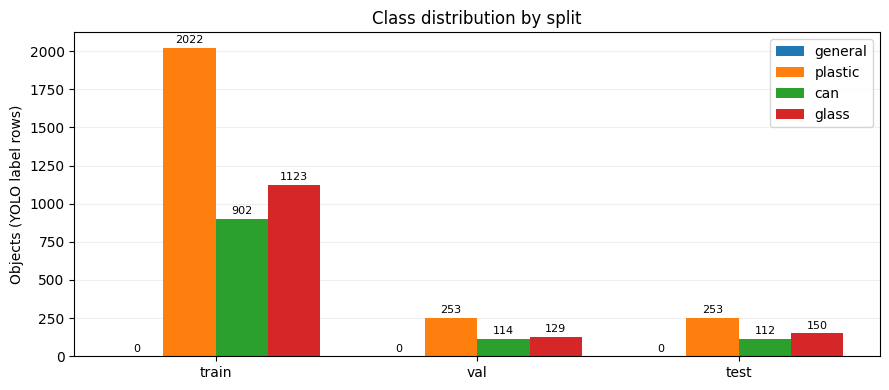

In [3]:
counts = {split: Counter(int(line.split()[0]) for label in (root / 'labels' / split).glob('*.txt')
                         for line in label.read_text(encoding='utf-8').splitlines() if line.strip())
          for split in splits}
image_counts = {split: len(list((root / 'images' / split).glob('*.jpg'))) for split in splits}
print(f"{'split':<8} {'images':>7} " + ' '.join(f'{name:>8}' for name in names.values()))
for split in splits:
    print(f"{split:<8} {image_counts[split]:>7} " + ' '.join(f'{counts[split][i]:>8}' for i in names))

fig, ax = plt.subplots(figsize=(9, 4))
x = range(len(splits))
for i, name in names.items():
    bars = ax.bar([j + (i - 1.5) * 0.2 for j in x], [counts[split][i] for split in splits],
                  width=0.2, label=name)
    ax.bar_label(bars, fontsize=8, padding=2)
ax.set_xticks(list(x), splits)
ax.set_ylabel('Objects (YOLO label rows)')
ax.set_title('Class distribution by split')
ax.legend()
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


## 클래스별 라벨 예시

train에서 각 클래스의 첫 라벨 이미지를 표시합니다. general은 예시가 없습니다.


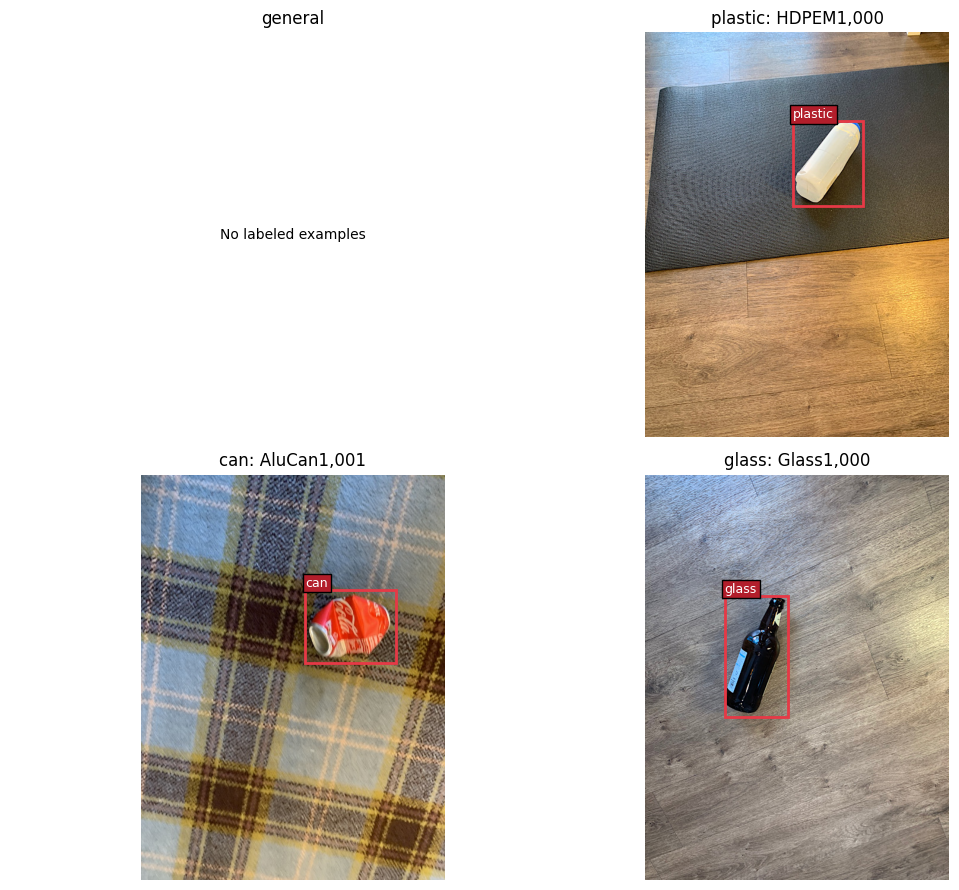

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
image_dir = root / 'images' / 'train'
image_files = {path.stem.lower(): path for path in image_dir.iterdir() if path.suffix.lower() == '.jpg'}
examples = {}
for label in sorted((root / 'labels' / 'train').glob('*.txt')):
    for row in label.read_text(encoding='utf-8').splitlines():
        examples.setdefault(int(row.split()[0]), label)
    if len(examples) == 3:
        break
for (class_id, name), ax in zip(names.items(), axes.flat):
    label = examples.get(class_id)
    if label is None:
        ax.text(0.5, 0.5, 'No labeled examples', ha='center', va='center')
        ax.set_title(name)
        ax.axis('off')
        continue
    image = Image.open(image_files[label.stem.lower()])
    image.thumbnail((900, 900))
    width, height = image.size
    ax.imshow(image)
    for row in label.read_text(encoding='utf-8').splitlines():
        parts = row.split()
        obj_id = int(parts[0])
        xc, yc, bw, bh = map(float, parts[1:])
        x, y = (xc - bw / 2) * width, (yc - bh / 2) * height
        ax.add_patch(Rectangle((x, y), bw * width, bh * height, fill=False, edgecolor='#e63946', linewidth=2))
        ax.text(x, max(0, y - 5), names[obj_id], color='white', fontsize=9,
                bbox={'facecolor': '#b21e2b', 'pad': 2})
    ax.set_title(f'{name}: {label.stem}')
    ax.axis('off')
plt.tight_layout()
plt.show()
